# 12 · Does better training data fix the real-world failures? (Milestone 7b)

**In one sentence:** we retrain the same two models with extra, more realistic training data, and measure whether the failures from Milestone 7 get smaller.

**Why:** Milestone 7 showed the domain-only models raise many false alarms on real websites (up to 81% for sites with a subdomain) and are easy to evade. We traced it to the **data**: PhiUSIIL's legitimate links are homepages with no subdomain, and its phishing comes from one feed. If that's the cause, better data should help. This notebook tests that claim instead of just stating it.

### What was added to training ("PhiUSIIL + fixes")
1. **Real legitimate websites:** a fixed half of the Tranco top-20k list.
2. **Legitimate subdomains:** copies of 25% of legitimate training domains with a prefix like `app.`, `docs.` or `help.`. These prefixes are **different** from the ones we test with (`mail.`, `blog.`, `login.` …), so the test stays fair.
3. **More, newer phishing:** 25,000 domains from Phishing.Database, one per site owner.
4. **Edited phishing:** copies of 25% of phishing training domains with one realistic attacker edit (Milestone 7's edits).

### How we test (the important part)
- **No test website shares a site owner with anything in training**, in either version. That's checked when the sets are built.
- Tests: PhiUSIIL's own test split; Chrome's most-visited sites (CrUX) and the other half of Tranco (false alarms); PhishTank phishing **submitted from 2025 on** (new phishing caught); and Milestone 7's two attacks.
- Same protocol as always: settings and threshold chosen on validation, 5 splits, mean ± sd.

**Where the numbers come from:** `python -m phishguard.datafix --model ngram` (Mac CPU, ~8 min) and `--model hybrid` (lab H100 GPU, ~25 min). This notebook only **reads** their results in `results/m7b/`. Code: `src/phishguard/datafix.py`, decision D18.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from phishguard.evaluate import RESULTS_DIR

MODELS = {"ngram": "Character n-grams", "hybrid": "Hybrid (CNN + features)"}
VARIANTS = {"phiusiil_only": "PhiUSIIL only", "phiusiil_plus_fixes": "PhiUSIIL + fixes"}
results = {(m, v): json.loads((RESULTS_DIR / "m7b" / f"{m}__{v}.json").read_text()) for m in MODELS for v in VARIANTS}

TESTS = {   # result key -> (plain name, what "flagged" means, is higher better?)
    "phiusiil_accuracy": ("PhiUSIIL test accuracy", "accuracy", True),
    "crux_bare": ("Popular plain domains (CrUX)", "false alarms", False),
    "crux_subdomain": ("Popular sites with a subdomain (CrUX)", "false alarms", False),
    "tranco_test": ("Tranco sites (test half)", "false alarms", False),
    "phiusiil_legit_plus_mail": ("Legitimate + mail.", "false alarms", False),
    "phishtank_new": ("New phishing, 2025–26 (PhishTank)", "caught", True),
    "phiusiil_phish_all_edits": ("Edited phishing", "caught", True),
}
print("splits:", results[("ngram", "phiusiil_only")]["seeds"])

splits: [42, 0, 1, 2, 3]


## Step 1 · The data sets
Sizes of the added training data and of each test set (distinct domains):

In [2]:
pools = results[("ngram", "phiusiil_plus_fixes")]["pools"]
r42 = results[("ngram", "phiusiil_plus_fixes")]["per_seed"][0]
sizes = pd.Series({
    "train: Tranco half A (legitimate)": pools["tranco_train"],
    "train: Phishing.Database (phishing)": pools["pdb_train"],
    "test: Tranco half B (legitimate)": pools["tranco_test"],
    "test: CrUX plain domains (legitimate)": pools["crux_bare"],
    "test: CrUX with a subdomain (legitimate)": pools["crux_subdomain"],
    "test: PhishTank 2025+ (phishing)": pools["phishtank_new"],
    "test: PhiUSIIL legitimate + mail.": r42["phiusiil_legit_plus_mail"]["domains"],
    "test: PhiUSIIL phishing, every edit": r42["phiusiil_phish_all_edits"]["domains"],
}, name="domains")
only = results[("ngram", "phiusiil_only")]["per_seed"][0]
print(f"training rows, seed 42: {only['train_rows']:,} (PhiUSIIL only) → {r42['train_rows']:,} (+ fixes); "
      f"phishing share {only['train_phishing_share']:.1%} → {r42['train_phishing_share']:.1%}")
sizes.to_frame()

training rows, seed 42: 164,045 (PhiUSIIL only) → 225,928 (+ fixes); phishing share 42.5% → 43.8%


,domains
train: Tranco half A (legitimate),8510
train: Phishing.Database (phishing),25000
test: Tranco half B (legitimate),8330
test: CrUX plain domains (legitimate),3851
test: CrUX with a subdomain (legitimate),1448
test: PhishTank 2025+ (phishing),7518
test: PhiUSIIL legitimate + mail.,20220
"test: PhiUSIIL phishing, every edit",9531


## Step 2 · Before and after, both models
Each cell is **mean ± sd over 5 splits**, in %. Read each row with its meaning: for *false alarms* lower is better; for *caught* and *accuracy* higher is better.

In [3]:
rows = []
for key, (name, meaning, higher) in TESTS.items():
    row = {"test": name, "measures": meaning}
    for m, label in MODELS.items():
        for v, vlabel in VARIANTS.items():
            s = results[(m, v)]["summary"][key]
            row[f"{label} | {vlabel}"] = f"{s['mean']*100:.1f} ± {s['sd']*100:.1f}"
    rows.append(row)
table = pd.DataFrame(rows).set_index("test")
table

,measures,Character n-grams | PhiUSIIL only,Character n-grams | PhiUSIIL + fixes,Hybrid (CNN + features) | PhiUSIIL only,Hybrid (CNN + features) | PhiUSIIL + fixes
test,,,,,
PhiUSIIL test accuracy,accuracy,86.3 ± 0.9,85.7 ± 0.9,86.8 ± 1.0,85.7 ± 1.0
Popular plain domains (CrUX),false alarms,22.2 ± 1.2,17.2 ± 3.7,15.8 ± 1.8,12.0 ± 1.6
Popular sites with a subdomain (CrUX),false alarms,53.4 ± 2.2,38.7 ± 4.5,76.8 ± 1.8,62.8 ± 1.3
Tranco sites (test half),false alarms,25.4 ± 1.5,15.7 ± 3.8,18.0 ± 1.9,9.8 ± 1.5
Legitimate + mail.,false alarms,67.1 ± 2.3,65.8 ± 6.4,86.4 ± 1.9,92.2 ± 1.4
"New phishing, 2025–26 (PhishTank)",caught,82.1 ± 0.7,81.3 ± 2.1,81.7 ± 0.6,81.4 ± 0.8
Edited phishing,caught,30.6 ± 1.7,38.7 ± 3.1,19.9 ± 4.2,27.4 ± 5.1


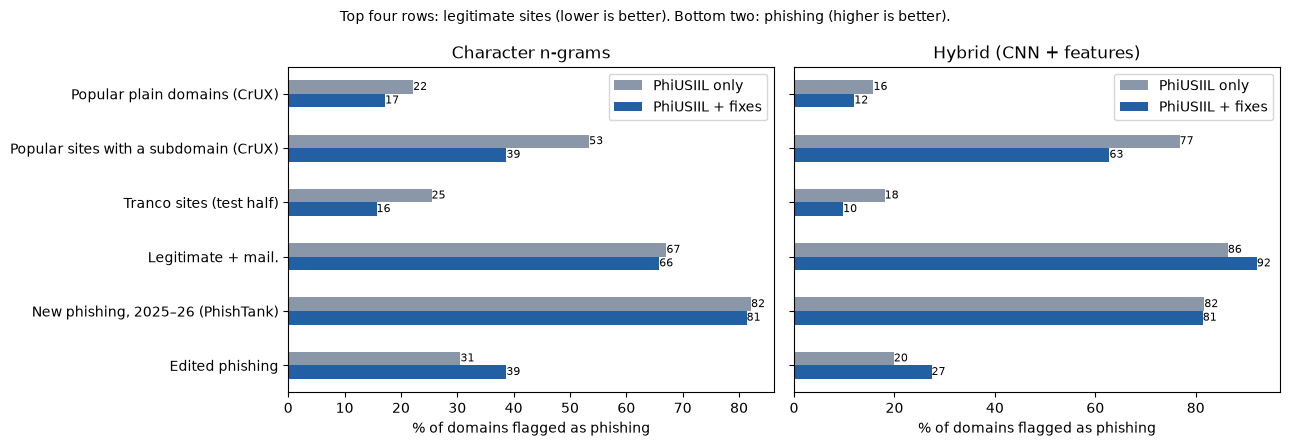

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
keys = ["crux_bare", "crux_subdomain", "tranco_test", "phiusiil_legit_plus_mail", "phishtank_new", "phiusiil_phish_all_edits"]
for ax, (m, label) in zip(axes, MODELS.items()):
    data = pd.DataFrame({VARIANTS[v]: [results[(m, v)]["summary"][k]["mean"] * 100 for k in keys] for v in VARIANTS},
                        index=[TESTS[k][0] for k in keys])
    data.plot.barh(ax=ax, color=["#8A97A8", "#235FA3"])
    ax.set_title(label)
    ax.set_xlabel("% of domains flagged as phishing")
    ax.invert_yaxis()
    for c in ax.containers:
        ax.bar_label(c, fmt="%.0f", fontsize=8)
fig.suptitle("Top four rows: legitimate sites (lower is better). Bottom two: phishing (higher is better).", fontsize=10)
plt.tight_layout()
plt.show()

## Step 3 · Is the change real, or split-to-split noise?
For each test, we count on how many of the 5 splits the fix moved the result in the good direction. Both versions use the same 5 splits, so this is a paired comparison: 5 of 5 is clear; 3 of 5 could be chance.

In [5]:
def per_seed(m, v, key):
    recs = results[(m, v)]["per_seed"]
    return [r["phiusiil_test"]["accuracy"] if key == "phiusiil_accuracy" else r[key]["flagged"] for r in recs]

rows = []
for key, (name, meaning, higher) in TESTS.items():
    row = {"test": name}
    for m, label in MODELS.items():
        before, after = per_seed(m, "phiusiil_only", key), per_seed(m, "phiusiil_plus_fixes", key)
        better = sum((a > b) if higher else (a < b) for b, a in zip(before, after))
        change = (sum(after) - sum(before)) / len(before) * 100
        row[label] = f"{change:+.1f} points, better on {better}/5"
    rows.append(row)
pd.DataFrame(rows).set_index("test")

,Character n-grams,Hybrid (CNN + features)
test,,
PhiUSIIL test accuracy,"-0.5 points, better on 0/5","-1.1 points, better on 0/5"
Popular plain domains (CrUX),"-5.0 points, better on 4/5","-3.8 points, better on 5/5"
Popular sites with a subdomain (CrUX),"-14.7 points, better on 5/5","-14.0 points, better on 5/5"
Tranco sites (test half),"-9.8 points, better on 5/5","-8.3 points, better on 5/5"
Legitimate + mail.,"-1.3 points, better on 4/5","+5.8 points, better on 0/5"
"New phishing, 2025–26 (PhishTank)","-0.8 points, better on 2/5","-0.3 points, better on 1/5"
Edited phishing,"+8.1 points, better on 5/5","+7.5 points, better on 5/5"


## Step 4 · Why did `mail.` get *worse* for the hybrid?
We count, in the seed-42 "PhiUSIIL + fixes" training set, how often each first word of a subdomain appears as legitimate vs phishing. (This rebuilds the training set from the frozen feeds, ~30 s.)

In [6]:
from phishguard.data import load_clean
from phishguard.datafix import build_pools, make_sets

df = load_clean()
train_domains, train_labels = make_sets(df, build_pools(df), 42, "PhiUSIIL + fixes")["train"]
first_word = train_domains.str.split(".").str[0]
has_subdomain = train_domains.str.count(r"\.") >= 2
counts = pd.DataFrame({
    word: {"legitimate": int(((first_word == word) & has_subdomain & (train_labels == 0)).sum()),
           "phishing": int(((first_word == word) & has_subdomain & (train_labels == 1)).sum())}
    for word in ["mail", "webmail", "login", "www2", "app", "docs", "help"]
}).T
counts

,legitimate,phishing
mail,1,597
webmail,0,23
login,0,96
www2,0,23
app,2520,89
docs,2593,534
help,2526,12


**Reading it:** `mail.` appears **almost only as phishing** in training (webmail login pages are a classic phishing target), and the Phishing.Database domains we added contain more of them. Our legitimate subdomains deliberately used other words (`app.`, `docs.` …) so the test would be fair. So the training data now holds *even more* evidence that "`mail.` means phishing", and the hybrid learned it more firmly. The n-gram model barely moved.

**The lesson:** adding data removes a bias only if the new data contains **counter-examples** to it. Adding data without checking what it teaches can make a bias worse.

## What we learned
1. **Better data helps, where it applies.** Both models raise clearly fewer false alarms on real websites: the hybrid's Tranco false alarms fall from 18% to 10%, and sites with a subdomain from 77% to 63% (n-grams: 53% → 39%). Edited phishing is caught more often. Step 3 shows how consistent each move is across the 5 splits.
2. **The cost is small:** about 0.6–1.1 points of PhiUSIIL accuracy, and new 2025–26 phishing is caught as often as before (~81%).
3. **Neither model wins everywhere:** after the fix, the hybrid has fewer false alarms on plain domains and Tranco, while n-grams handle subdomains and edits better.
4. **It's a partial fix.** 39–63% false alarms on sites with a subdomain is still far from usable, and `mail.` got worse for the hybrid, for a reason we can show in the data (Step 4).
5. This supports the project's thesis from the other direction: the limit is the data. Changing the data changes the failures, in the direction the new data points.